# Cesium fluorescence/absorption: select a file and rerun

**Default input: the upward-going cloud (`2026-10-06_0041_exp11_switchArmsAndLaunch_0.h5`).**

Change **`FILE_PATH` in the first code cell**, then **Restart Kernel and Run All** to analyze another recording from this acquisition setup. The same code handles both the upward-going `_0.h5` and returning `_1.h5` acquisitions. Plots, reference fitting, cloud search, timing tables, and exports all follow the selected input; no other cell needs a filename change.

The shared, commented implementation is `fluorescence_absorption_lockin.py` beside this notebook. Keep that file with the notebooks. Each input gets its own `lockin_analysis_outputs/<input filename without .h5>/` directory. HDF5 files are opened read-only.

The steps are: detector time traces, raw frequency spectra, measured-reference fitting, 2/4 kHz complex lock-in, time-domain candidate peaks, averaging sensitivity, and numerical checks. Weak returning data are evaluated against off-cloud fluctuations rather than treating every positive magnitude maximum as a detected absorption peak.

**Units:** PDA100A2 (`TOF_florescence`) is in Volts. `photon_counts` contains cumulative integers: differences divided by the 10 μs interval give PMT counts/s. A PMT voltage plot requires a separate calibration.

**Plot display:** `%matplotlib widget` provides live, resizable canvases with automatic widget layout and no explicit display `figsize`. All plot text, including ticks, labels, titles, and legends, uses a normal-weight 12-point font. Complex lock-in plots use separate PMT and PDA figures with full-width panels and shared legends outside the data area. Every x-axis label has 20-point padding. The PNG export sizes are independent of the display size. [ipympl canvas display and resizing](https://matplotlib.org/ipympl/examples/full-example.html).

In [2]:
# Import numerical, plotting, and notebook-display tools.
import os
import sys
import importlib
from pathlib import Path
#os.environ.setdefault("MPLCONFIGDIR", "/tmp/mpl-cesium-lockin")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import display, Markdown

# CHANGE ONLY THIS INPUT for another exp11 recording from the same acquisition setup.
# FILE_PATH = Path("/home/bgodfrey/LBL/EDM/Code/Labscript_Data/Florescence_Absorption_10-6-26/2026-10-06_0041_exp11_switchArmsAndLaunch_0.h5")
FILE_PATH = Path(r"C:\Experiments\eedmLabscriptOps\exp12_switchArmsAndLaunch_Absorption\2026\10\15\0002\2026-10-15_0002_exp12_switchArmsAndLaunch_Absorption_1.h5")
if not FILE_PATH.is_file():
    raise FileNotFoundError(FILE_PATH)
DATA_DIR = FILE_PATH.parent

# Import the same commented helper module for every selected file, even from another working directory.
if str(DATA_DIR) not in sys.path:
    sys.path.insert(0, str(DATA_DIR))
# Refresh the helper when Run All is used in a kernel that imported an older version.
import fluorescence_absorption_lockin as lockin_helper
importlib.reload(lockin_helper)
from fluorescence_absorption_lockin import (
    load_shot, triangular_kernel, fit_modulation_reference, complex_lockin, analyze_shot,
)

# The label is presentation only; it never changes filtering or peak-finding behavior.
SHOT_LABEL = {"2026-10-06_0041_exp11_switchArmsAndLaunch_0.h5": "Upward-going",
              "2026-10-06_0041_exp11_switchArmsAndLaunch_1.h5": "Returning"}.get(
                  FILE_PATH.name, FILE_PATH.stem)

# Shared physical and analysis settings; these defaults are identical for both acquisitions.
EXPECTED_FS_HZ = None        # NI AI rate: None uses the file's acquisition_rate (100k, 500k, or 250k with ai2 in use).
FM_HZ = 6123.0
SINE_DURATION_S = 0.100
ENABLE_DURATION_S = 0.070
HARMONICS = (1, 2)
AVERAGING_PERIODS = 2        # Each boxcar averages two periods: 1 ms at 2 kHz.
SWITCH_GUARD_S = 0.001       # Additional guard beyond the finite filter support.
CLOUD_HALF_WIDTH_S = 0.008  # Search ±8 ms around the independently measured PMT peak.
BACKGROUND_GUARD_S = 0.002  # Separate background samples from the cloud window.
ANALYSIS_OPTIONS = dict(cloud_half_width_s=CLOUD_HALF_WIDTH_S,
                        background_guard_s=BACKGROUND_GUARD_S,
                        switch_guard_s=SWITCH_GUARD_S, harmonics=HARMONICS)

# Every file gets its own export directory, so switching inputs does not overwrite another shot.
SAVE_OUTPUTS = True
OUTPUT_DIR = DATA_DIR / "lockin_analysis_outputs" / FILE_PATH.stem
if SAVE_OUTPUTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Use live ipympl canvases with automatic widget layout and no fixed display figsize.
%matplotlib widget
# Explicit display below avoids a second automatically displayed copy of each canvas.
plt.ioff()
plt.rcParams.update({"figure.dpi": 110, "font.size": 12, "axes.grid": True,
                     "grid.alpha": 0.25, "lines.linewidth": 1.0,
                     "axes.labelsize": 12, "axes.titlesize": 12,
                     "figure.titlesize": 12, "legend.fontsize": 12,
                     "font.weight": "normal", "axes.labelweight": "normal",
                     "axes.titleweight": "normal", "figure.titleweight": "normal",
                     "xtick.labelsize": 12, "ytick.labelsize": 12})

# Apply the requested font settings consistently to labels, titles, and legends.
label_font = {
    "fontname": "sans-serif",
    "size": 12,
    "color": "black",
    "weight": "normal",
    "verticalalignment": "bottom",
}
title_font = {
    "fontname": "sans-serif",
    "size": 12,
    "color": "black",
    "weight": "normal",
}
legend_font = {
    "family": "sans-serif",
    "size": 12,
    "style": "normal",
    "weight": "normal",
}

# These sizes apply only while writing PNG files, then the display size is restored.
EXPORT_SIZES_INCHES = {
    "time_traces": (14, 12),
    "modulation_reference": (14, 12),
    "frequency_spectra": (18, 12),
    "lockin_xy_amplitude_pmt": (14, 12),
    "lockin_xy_amplitude_pda100a2": (14, 12),
    "cloud_peak_zoom": (16, 16),
    "averaging_sensitivity": (17, 7),
}

def show_figure(fig, name):
    """Export at a separate size and display the live, resizable widget canvas."""
    if SAVE_OUTPUTS:
        # forward=False keeps export sizing from requesting a front-end canvas resize.
        display_size = fig.get_size_inches().copy()
        try:
            fig.set_size_inches(EXPORT_SIZES_INCHES[name], forward=False)
            fig.savefig(OUTPUT_DIR / f"{name}.png", dpi=180, bbox_inches="tight")
        finally:
            fig.set_size_inches(display_size, forward=False)

    # Let the widget layout use the notebook's available width; height is automatic.
    fig.canvas.layout.width = "100%"
    fig.canvas.layout.height = "auto"
    fig.canvas.resizable = True
    fig.canvas.toolbar_visible = True
    # A toolbar on the left overlaps a full-width canvas; above the figure it never covers the axes.
    fig.canvas.toolbar_position = "top"
    fig.canvas.header_visible = False
    display(fig.canvas)
    # Keep the figure open: closing it here would remove the interactive widget.


## Read the selected acquisition's timing

The script programs `0.01*sin(2*pi*2000*(t - t_sine)) + 0.007` Volts. The `Jump to blue` marker locates the sine relative to the selected acquisition. The AO sine lasts 100 ms, while `MAIN_REL_JUMP_do` is enabled for its first 70 ms. This acquisition setup therefore has a sine at **43–143 ms** and a physical enable interval at **43–113 ms after acquisition starts**.

The acquisition delay is read from each file: **16 ms after drop for `_0`**, **484 ms for returning `_1`**. Consequently, the returning sine is at 527–627 ms after drop and the enable interval is 527–597 ms. The following table is calculated from the selected file rather than copied from the upward result.

Analog timestamps include a shot-time origin and a wait; PMT timestamps are local. Subtract each analog trace's first timestamp and align the PMT with its stored commanded start. Drop-relative times use commanded acquisition start minus `drop_time`; hardware/channel delays are not independently calibrated. The returning acquisition is a cloud observation, not an atom-free reference.

**Displayed time axis:** every time-domain plot is now in **milliseconds after `drop_time`**. Returning data begin at **484 ms**, and upward data begin at **16 ms**. The 484 ms return delay is included in raw traces, modulation gates, lock-in curves, peak markers, zoom limits, and annotations. Analysis-local times remain available in explicitly labeled table columns and CSV exports.

In [3]:
# Load exactly the selected file; the HDF5 input is opened read-only.
shot = load_shot(FILE_PATH, expected_fs_hz=EXPECTED_FS_HZ,
                 sine_duration_s=SINE_DURATION_S, enable_duration_s=ENABLE_DURATION_S)

# exp12 shots record the modulation frequency as a global; exp11 shots keep the FM_HZ default.
if shot.get("mod_freq") is not None:
    FM_HZ = shot["mod_freq"]

# Support rerunning this cell with an older loader still held by an open kernel.
# Read the actual PMT delay from HDF5 metadata rather than assuming an acquisition offset.
if "pmt_delay_s" not in shot:
    import h5py
    with h5py.File(FILE_PATH, "r") as h5:
        shot["pmt_delay_s"] = float(h5["globals"].attrs["t_PMT_delay"])

# All displayed times include the acquisition delay read from this selected file.
# For returning data, the first PDA sample is 484 ms after drop_time (PMT interval center: 484.005 ms).
def time_after_drop_ms(acquisition_time_s):
    """Convert analysis-local seconds to displayed milliseconds after drop_time."""
    return 1e3 * (np.asarray(acquisition_time_s) + shot["acquisition_after_drop_s"])

metadata_table = pd.DataFrame([{
    "File": FILE_PATH.name, "PDA samples": len(shot["t_pda"]),
    "PMT count intervals": len(shot["t_pmt"]), "Sample rate (Hz)": shot["fs_pda"],
    "PMT delay (ms)": 1e3 * shot["pmt_delay_s"],
    "Acquisition start after drop (ms)": 1e3 * shot["acquisition_after_drop_s"],
    "Sine start after acquisition (ms)": 1e3 * shot["sine_start_s"],
    "Sine stop after acquisition (ms)": 1e3 * shot["sine_stop_s"],
    "Enable stop after acquisition (ms)": 1e3 * shot["enable_stop_s"],
    "Cumulative photons at end": int(shot["cumulative_counts"][-1]),
    "Modulation frequency (Hz)": FM_HZ,
    "mod_amp (V)": shot.get("mod_amp"), "mod_offset (V)": shot.get("mod_offset"),
    "PDA gain (dB)": shot.get("pda_gain_db"), "Probe power (μW)": shot.get("probe_power_uW"),
}]).set_index("File")
display(metadata_table.round(3))
print(f"Selected file: {FILE_PATH}")
print("PMT: cumulative integer counts converted to counts/s. PDA/reference: Volts.")
display(Markdown(
    f"**{SHOT_LABEL} timing:** acquisition starts "
    f"{1e3 * shot['acquisition_after_drop_s']:.3f} ms after drop. "
    f"Every time-domain plot uses this drop_time clock. The sine runs "
    f"{time_after_drop_ms(shot['sine_start_s']):.3f}–{time_after_drop_ms(shot['sine_stop_s']):.3f} ms "
    f"after drop; the switch is enabled until {time_after_drop_ms(shot['enable_stop_s']):.3f} ms."
))

,PDA samples,PMT count intervals,Sample rate (Hz),PMT delay (ms),Acquisition start after drop (ms),Sine start after acquisition (ms),Sine stop after acquisition (ms),Enable stop after acquisition (ms),Cumulative photons at end,Modulation frequency (Hz),mod_amp (V),mod_offset (V),PDA gain (dB),Probe power (μW)
File,,,,,,,,,,,,,,
2026-10-15_0002_exp12_switchArmsAndLaunch_Absorption_1.h5,50000,14999,250000.0,484.0,484.0,43.0,143.0,113.0,81998,6125.0,0.0,0.01,60.0,80.0


Selected file: C:\Experiments\eedmLabscriptOps\exp12_switchArmsAndLaunch_Absorption\2026\10\15\0002\2026-10-15_0002_exp12_switchArmsAndLaunch_Absorption_1.h5
PMT: cumulative integer counts converted to counts/s. PDA/reference: Volts.


**2026-10-15_0002_exp12_switchArmsAndLaunch_Absorption_1 timing:** acquisition starts 484.000 ms after drop. Every time-domain plot uses this drop_time clock. The sine runs 527.000–627.000 ms after drop; the switch is enabled until 597.000 ms.

## Selected-file time traces

Show the full recorded voltage baseline instead of removing a fitted absorption background. A slow drift is visible in the PDA100A2; the narrow fluorescence feature helps identify the cloud independently. The PMT smoothing below is for display and for defining a search window, not for computing its frequency spectrum.

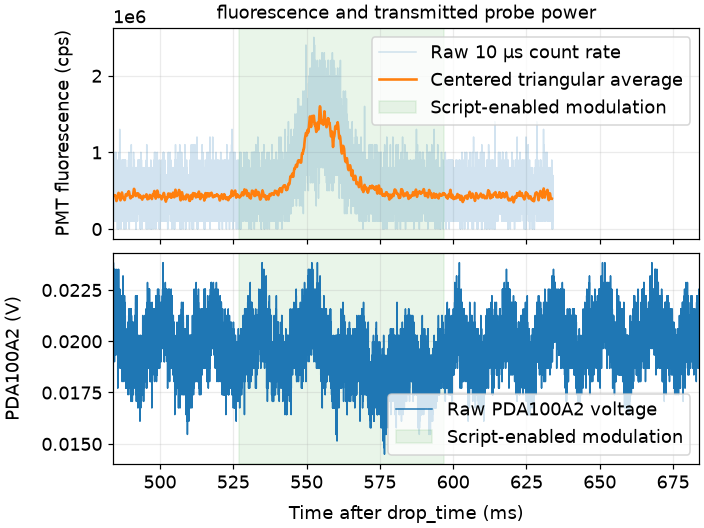

In [4]:
# Average the PMT over two modulation periods per boxcar, without changing the raw trace.
pmt_display_kernel, _ = triangular_kernel(shot["fs_pmt"], FM_HZ, AVERAGING_PERIODS)
pmt_display_smooth = signal.fftconvolve(shot["pmt_rate"], pmt_display_kernel, mode="same")
pmt_half_support_s = (len(pmt_display_kernel) - 1) / (2 * shot["fs_pmt"])
pmt_display_valid = ((shot["t_pmt"] >= shot["t_pmt"][0] + pmt_half_support_s)
                     & (shot["t_pmt"] <= shot["t_pmt"][-1] - pmt_half_support_s))

# Independently locate a preliminary fluorescence maximum for the reference-detail plot.
pmt_search = pmt_display_valid & (shot["t_pmt"] >= shot["enable_start_s"] + SWITCH_GUARD_S) & (shot["t_pmt"] <= shot["enable_stop_s"] - SWITCH_GUARD_S)
pmt_preliminary_s = float(shot["t_pmt"][np.flatnonzero(pmt_search)[np.argmax(pmt_display_smooth[pmt_search])]])

# Use separate y axes because PMT count rate and photodiode voltage are different observables.
fig, axes = plt.subplots(2, 1, sharex=True, layout="constrained")
axes[0].plot(time_after_drop_ms(shot["t_pmt"]), shot["pmt_rate"], alpha=0.20, label="Raw 10 μs count rate")
axes[0].plot(time_after_drop_ms(shot["t_pmt"][pmt_display_valid]), pmt_display_smooth[pmt_display_valid],
             color="C1", lw=1.7, label="Centered triangular average")
axes[0].set_ylabel("PMT fluorescence (cps)", fontdict=label_font, labelpad=12)
axes[1].plot(time_after_drop_ms(shot["t_pda"]), shot["pda_v"], label="Raw PDA100A2 voltage")
axes[1].set_ylabel("PDA100A2 (V)", fontdict=label_font, labelpad=12)
for ax in axes:
    ax.axvspan(time_after_drop_ms(shot["enable_start_s"]), time_after_drop_ms(shot["enable_stop_s"]),
               color="C2", alpha=0.10, label="Script-enabled modulation")
    ax.legend(loc="best", prop=legend_font)
axes[0].set_title(f"fluorescence and transmitted probe power", fontdict=title_font)
axes[-1].set_xlabel("Time after drop_time (ms)", fontdict=label_font, labelpad=20)
axes[-1].set_xlim(time_after_drop_ms(0), time_after_drop_ms(shot["t_pda"][-1]))

show_figure(fig, "time_traces")

## Measured modulation reference

Fit the recorded `RelJumpModulation` to an offset, slow linear drift, and a sinusoid near 2 kHz. Both sine and cosine coefficients are fit, so the phase does not need to be guessed from a detector response. The reference continues oscillating after the switch is disabled; fitting it there improves the reference estimate but does not extend the physical lock-in analysis interval.

The measured DC voltage can differ from the programmed 7 mV. It is not converted into optical detuning because no voltage-to-frequency calibration is specified for these data.

,Frequency (Hz),Peak amplitude (mV),DC at fit midpoint (mV),Sine phase at scheduled start (deg),Reference fit residual RMS (mV)
File,,,,,
2026-10-15_0002_exp12_switchArmsAndLaunch_Absorption_1.h5,6121.994,0.0086,6.6457,-100.9848,1.2767


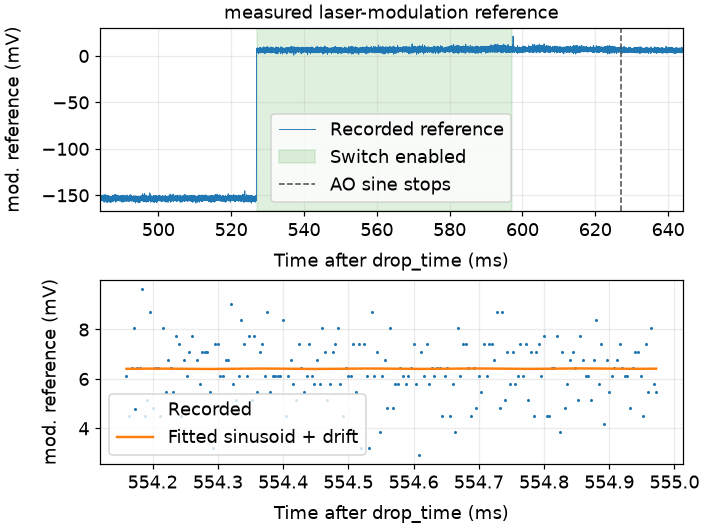

In [5]:
# Fit phase from the measured modulation channel, independently of either detector response.
reference = fit_modulation_reference(shot, frequency_guess_hz=FM_HZ)
reference_table = pd.DataFrame([{
    "File": FILE_PATH.name, "Frequency (Hz)": reference["f_hz"],
    "Peak amplitude (mV)": 1e3 * reference["amp_v"],
    "DC at fit midpoint (mV)": 1e3 * reference["offset_v"],
    "Sine phase at scheduled start (deg)": np.rad2deg(reference["phase_rad"]),
    "Reference fit residual RMS (mV)": 1e3 * reference["residual_rms_v"],
}]).set_index("File")
display(reference_table.round(4))

# Inspect the entire reference and five cycles near the expected cloud transit.
fig, axes = plt.subplots(2, 1, layout="constrained")
t = shot["t_pda"]
axes[0].plot(time_after_drop_ms(t), 1e3 * shot["reference_v"], lw=0.6, label="Recorded reference")
axes[0].axvspan(time_after_drop_ms(shot["enable_start_s"]), time_after_drop_ms(shot["enable_stop_s"]),
                color="C2", alpha=0.15, label="Switch enabled")
axes[0].axvline(time_after_drop_ms(shot["sine_stop_s"]), ls="--", color="0.3", label="AO sine stops")
axes[0].set_xlim(time_after_drop_ms(0), time_after_drop_ms(min(shot["t_pda"][-1], shot["sine_stop_s"] + 0.017)))
zoom = np.abs(t - pmt_preliminary_s) <= 2.5 / reference["f_hz"]
axes[1].plot(time_after_drop_ms(t[zoom]), 1e3 * shot["reference_v"][zoom], ".", ms=2, label="Recorded")
axes[1].plot(time_after_drop_ms(t[zoom]), 1e3 * reference["fit_v"][zoom],
             color="C1", lw=1.6, label="Fitted sinusoid + drift")
for ax in axes:
    ax.set_ylabel("mod. reference (mV)", fontdict=label_font, labelpad=12)
    ax.set_xlabel("Time after drop_time (ms)", fontdict=label_font, labelpad=20)
    ax.legend(loc="best", prop=legend_font)
axes[0].set_title(f"measured laser-modulation reference", fontdict=title_font)
show_figure(fig, "modulation_reference")

## Selected-file frequency spectra

The spectra use **raw** PDA voltages and **unsmoothed counter increments divided by 10 μs**, restricted to the settled, script-enabled modulation interval. A Hann-windowed one-sided periodogram is shown as amplitude spectral density (the square root of PSD). The PMT axis is `(counts/s)/√Hz`; the PDA axis is `V/√Hz`. A transient cloud produces a band around each carrier rather than necessarily a single narrow spectral line.

Native frequency spacing is printed below. There is no zero padding or conversion of voltage into optical power. Slow baseline variations remain in the spectrum after removing a constant mean.

PMT: 6,736 samples, native spacing 14.846 Hz
PDA100A2: 16,839 samples, native spacing 14.846 Hz


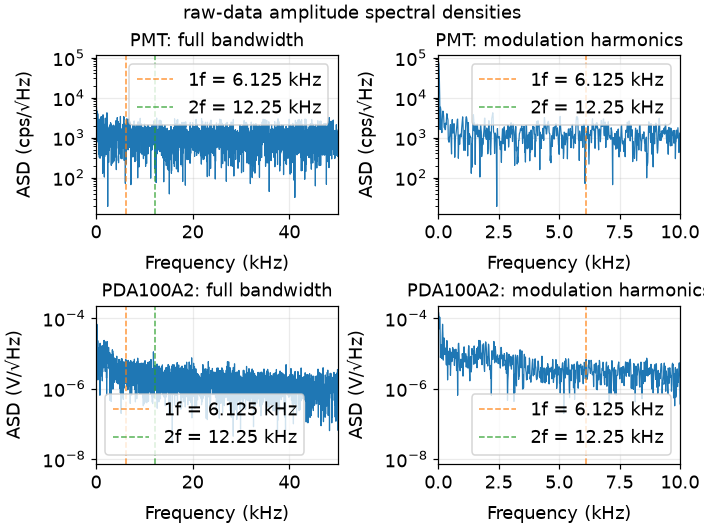

In [6]:
# Define a settled interval for spectral comparisons, excluding filter support and switch steps.
primary_kernel, primary_n = triangular_kernel(shot["fs_pda"], reference["f_hz"],
                                             AVERAGING_PERIODS)
primary_guard_s = SWITCH_GUARD_S + (len(primary_kernel) - 1) / (2 * shot["fs_pda"])
spectra = {}
for channel, time_key, value_key, fs_key in [
    ("PMT", "t_pmt", "pmt_rate", "fs_pmt"),
    ("PDA100A2", "t_pda", "pda_v", "fs_pda"),
]:
    times = shot[time_key]
    keep = ((times >= shot["enable_start_s"] + primary_guard_s)
            & (times <= shot["enable_stop_s"] - primary_guard_s))
    # Compute PSD from the full-rate data, independently of the displayed PMT smoothing.
    f, psd = signal.periodogram(shot[value_key][keep], fs=shot[fs_key], window="hann",
                                detrend="constant", scaling="density", return_onesided=True)
    spectra[channel] = {"f": f, "asd": np.sqrt(psd), "samples": int(keep.sum())}
    print(f"{channel}: {keep.sum():,} samples, native spacing {f[1] - f[0]:.3f} Hz")

# Pair a complete 0–50 kHz spectrum with a detailed 0–10 kHz view for each detector.
fig, axes = plt.subplots(2, 2, layout="constrained")
for row, channel in enumerate(("PMT", "PDA100A2")):
    spectrum = spectra[channel]
    for col, upper_khz in enumerate((50, 10)):
        ax = axes[row, col]
        nonzero = spectrum["f"] > 0
        ax.semilogy(spectrum["f"][nonzero] / 1e3, spectrum["asd"][nonzero], lw=0.8)
        for h in HARMONICS:
            ax.axvline(h * FM_HZ / 1e3, color=f"C{h}", ls="--", alpha=0.8,
                       label=f"{h}f = {h * FM_HZ / 1e3:g} kHz")
        ax.set_xlim(0, upper_khz)
        ax.set_xlabel("Frequency (kHz)", fontdict=label_font, labelpad=20)
        ax.set_ylabel("ASD (cps/√Hz)" if channel == "PMT" else "ASD (V/√Hz)", fontdict=label_font, labelpad=12)
        ax.set_title(f"{channel}: {'full bandwidth' if col == 0 else 'modulation harmonics'}", fontdict=title_font)
        ax.legend(prop=legend_font)
fig.suptitle(f"raw-data amplitude spectral densities", **title_font)
show_figure(fig, "frequency_spectra")

## Complex lock-in and peak definition

Use the measured reference phase $\theta(t)$ to calculate

$$Z_h(t)=2\,\mathrm{LPF}\{[v(t)-\mathrm{median}(v)]e^{-ih\theta(t)}\},\qquad
X_h=\Re Z_h,\quad Y_h=\Im Z_h,\quad R_h=|Z_h-Z_{h,\mathrm{bg}}|.$$

The factor of **2** makes a pure sinusoid of peak amplitude $A$ give $|Z|=A$. The low-pass filter is the symmetric triangular kernel formed from two boxcars; the default boxcar is **1 ms**, and the total kernel spans about **2 ms**. Centered offline filtering has no causal time delay, but broadens a narrow cloud feature. Finite rejection of the twice-carrier mixing term can also leave a small ripple and shift a waveform maximum, as quantified by the numerical check below. We exclude every sample whose filter overlaps an acquisition boundary or modulation switch, with an additional 1 ms switching guard.

The PMT's smoothed maximum in the enabled interval defines an **independent cloud window** (±8 ms). The lock-in background is a constant complex mean from the remaining settled interval, separated by a 2 ms guard. We retain reference-defined X and Y without rotating them to make a selected peak positive. **R is positive even for noise**; peak/background complex RMS is a descriptive contrast, not a Gaussian significance or a calibrated measurement of absorption depth.

Both harmonics are inspected because a symmetric absorption line at zero mean detuning can suppress the fundamental, whereas an offset produces a strong 2 kHz response. The real data decide which harmonic is useful.

PMT delay: 484.000 ms after drop_time.
PMT smoothed fluorescence peak: 554.565 ms after drop_time.
PDA valid lock-in interval: 528.32–595.68 ms after drop_time.


Units  Peak after acquisition (ms)  \
Channel  Harmonic                                          
PMT      1         counts/s                       68.025   
         2         counts/s                       72.925   
PDA100A2 1                V                       63.460   
         2                V                       76.144   

                   Peak after drop (ms)  Peak amplitude  \
Channel  Harmonic                                         
PMT      1                      552.025   257618.649424   
         2                      556.925   235022.468987   
PDA100A2 1                      547.460        0.000534   
         2                      560.144        0.000518   

                   Background complex RMS  Background max amplitude  \
Channel  Harmonic                                                     
PMT      1                   62323.816319             188398.468695   
         2                   61958.122194             148731.945766   
PDA100A2 1                       0.000241                  0.000653   
         2                       0.000177                  0.000462   

                   Peak/background RMS  \
Channel  Harmonic                        
PMT      1                    4.133551   
         2                    3.793247   
PDA100A2 1                    2.213015   
         2                    2.928581   

                   Largest peak in full settled gate after acquisition (ms)  \
Channel  Harmonic                                                             
PMT      1                                                    68.025          
         2                                                    72.925          
PDA100A2 1                                                    92.384          
         2                                                    76.144          

                   Largest peak in full settled gate after drop (ms)  \
Channel  Harmonic                                                      
PMT      1                                                   552.025   
         2                                                   556.925   
PDA100A2 1                                                   576.384   
         2                                                   560.144   

                   Phase at peak (deg)  Boxcar length (ms)  
Channel  Harmonic                                           
PMT      1                 -134.730435               0.330  
         2                  -78.005931               0.330  
PDA100A2 1                  -34.611717               0.328  
         2                  113.187737               0.328

**2026-10-15_0002_exp12_switchArmsAndLaunch_Absorption_1: phase-preserving complex lock-in**

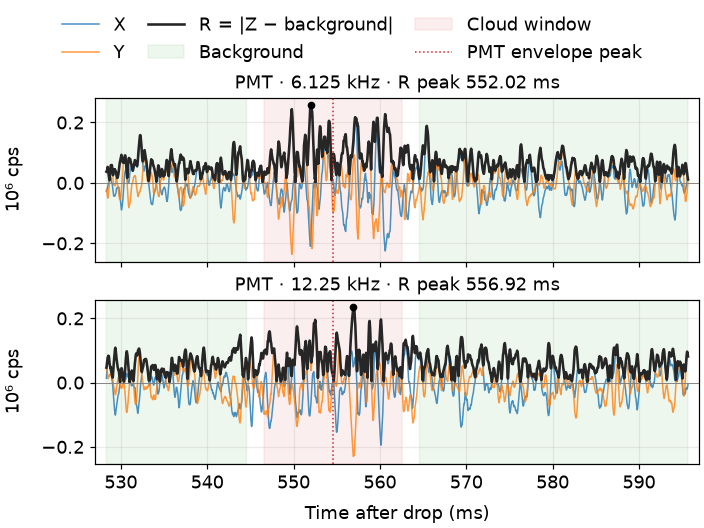

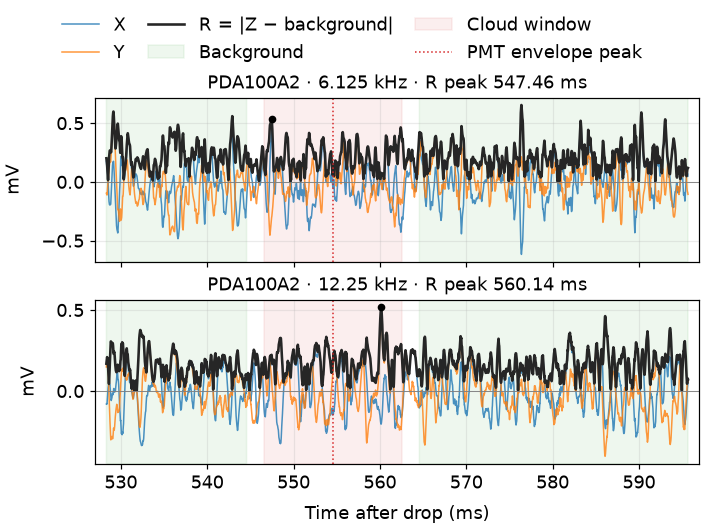

In [7]:
# Analyze only the selected file using the shared functions and explicit settings.
primary = analyze_shot(shot, reference, n_periods=AVERAGING_PERIODS, **ANALYSIS_OPTIONS)
print(f"PMT delay: {1e3 * shot['pmt_delay_s']:.3f} ms after drop_time.")
print(f"PMT smoothed fluorescence peak: {time_after_drop_ms(primary['pmt_peak_s']):.3f} ms after drop_time.")
pda_valid_result = primary["results"][("PDA100A2", 1)]
pda_valid_time_ms = time_after_drop_ms(pda_valid_result["t"][pda_valid_result["valid"]])
print(f"PDA valid lock-in interval: {pda_valid_time_ms[0]:.2f}–{pda_valid_time_ms[-1]:.2f} ms after drop_time.")
display(primary["table"].set_index(["Channel", "Harmonic"]).round(6))

# Show full-width panels in separate PMT and PDA figures so the data remain readable.
# A shared legend above each pair leaves every plotted sample unobscured.
display(Markdown(f"**{SHOT_LABEL}: phase-preserving complex lock-in**"))
for channel in ("PMT", "PDA100A2"):
    fig, axes = plt.subplots(len(HARMONICS), 1, sharex=True, squeeze=False,
                             layout="constrained")
    for ax, h in zip(axes[:, 0], HARMONICS):
        result = primary["results"][(channel, h)]
        valid = result["valid"]
        t_ms = time_after_drop_ms(result["t"][valid])
        scale = 1e-6 if channel == "PMT" else 1e3
        ax.plot(t_ms, scale * result["z"].real[valid], alpha=0.8, label="X")
        ax.plot(t_ms, scale * result["z"].imag[valid], alpha=0.8, label="Y")
        ax.plot(t_ms, scale * result["r"][valid], color="0.15", lw=1.7,
                label="R = |Z − background|")
        # Shade background and cloud regions lightly, keeping the traces prominent.
        bg = valid & result["background_mask"]
        ax.fill_between(time_after_drop_ms(result["t"]), 0, 1, where=bg,
                        transform=ax.get_xaxis_transform(), color="C2", alpha=0.08,
                        label="Background")
        ax.axvspan(time_after_drop_ms(primary["cloud_center_s"] - CLOUD_HALF_WIDTH_S),
                   time_after_drop_ms(primary["cloud_center_s"] + CLOUD_HALF_WIDTH_S),
                   color="C3", alpha=0.08, label="Cloud window")
        ax.axvline(time_after_drop_ms(primary["pmt_peak_s"]), color="C3", ls=":",
                   label="PMT envelope peak")
        ax.plot(time_after_drop_ms(result["peak_time_s"]), scale * result["peak_amp"],
                "o", color="black", markersize=4)
        # Keep each title short enough for a notebook-width panel.
        ax.set_title(f"{channel} · {h * FM_HZ / 1e3:g} kHz · "
                     f"R peak {time_after_drop_ms(result['peak_time_s']):.2f} ms",
                     fontdict=title_font)
        ax.set_ylabel("10⁶ cps" if channel == "PMT" else "mV",
                      fontdict=label_font, labelpad=12)
        ax.set_xlim(time_after_drop_ms(shot["enable_start_s"]),
                    time_after_drop_ms(shot["enable_stop_s"]))
        ax.axhline(0, color="0.5", lw=0.6)
    axes[-1, 0].set_xlabel("Time after drop (ms)", fontdict=label_font, labelpad=20)
    # Constrained layout reserves space above the axes for this figure-level legend.
    # Reuse the first panel's handles instead of repeating a legend on each axis.
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside upper center", ncols=3,
               frameon=False, prop=legend_font, columnspacing=1.2, handlelength=2)
    show_figure(fig, f"lockin_xy_amplitude_{channel.lower()}")


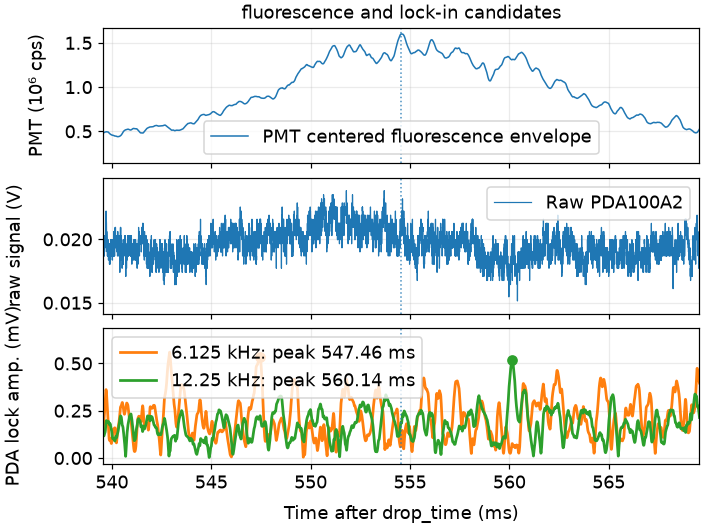

,Peak after drop (ms),Peak after acquisition (ms),Peak amplitude,Background complex RMS,Peak/background RMS,Peak/background max,Largest peak in full settled gate after drop (ms)
Harmonic,,,,,,,
1,547.460,63.460,0.000534,0.000241,2.213015,0.817890,576.384
2,560.144,76.144,0.000518,0.000177,2.928581,1.121558,560.144


**2026-10-15_0002_exp12_switchArmsAndLaunch_Absorption_1 result:** the 2 kHz cloud-window maximum is **547.46 ms after drop_time**, with amplitude **0.534 mV**. Off-cloud complex RMS is 0.241 mV, and the largest off-cloud fluctuation is 0.653 mV. The PMT fluorescence envelope peaks at 554.565 ms after drop_time. The 4 kHz candidate is 0.518 mV at 560.14 ms after drop_time.

The peak/background ratios are descriptive contrasts, not detection significances. The full-gate maximum and off-cloud fluctuations help distinguish an isolated transit feature from a magnitude peak that is comparable to noise. Lock-in amplitudes are Fourier components of the detector signal; they are not the full optical dip depth.

In [8]:
# Present the absorption peak alongside fluorescence on the same time axis.
pda_f = primary["results"][("PDA100A2", 1)]
pda_2f = primary["results"][("PDA100A2", 2)]
fig, axes = plt.subplots(3, 1, sharex=True, layout="constrained")
axes[0].plot(time_after_drop_ms(shot["t_pmt"]), primary["pmt_smooth"] / 1e6, color="C0",
             label="PMT centered fluorescence envelope")
axes[0].set_ylabel("PMT (10⁶ cps)", fontdict=label_font, labelpad=12)
axes[1].plot(time_after_drop_ms(shot["t_pda"]), shot["pda_v"], lw=0.8, label="Raw PDA100A2")
axes[1].set_ylabel("raw signal (V)", fontdict=label_font, labelpad=12)
for h, result, color in [(1, pda_f, "C1"), (2, pda_2f, "C2")]:
    valid = result["valid"]
    axes[2].plot(time_after_drop_ms(result["t"][valid]), 1e3 * result["r"][valid], color=color,
                 lw=1.8, label=f"{h * FM_HZ / 1e3:g} kHz: peak {time_after_drop_ms(result['peak_time_s']):.2f} ms")
    axes[2].plot(time_after_drop_ms(result["peak_time_s"]), 1e3 * result["peak_amp"], "o", color=color)
axes[2].set_ylabel("PDA lock amp. (mV)", fontdict=label_font, labelpad=20)
for ax in axes:
    ax.axvline(time_after_drop_ms(primary["pmt_peak_s"]), color="C0", ls=":", alpha=0.8)
    ax.legend(loc="best", prop=legend_font)
axes[0].set_title(f"fluorescence and lock-in candidates", fontdict=title_font)
# Use the independently found transit to choose the zoom, regardless of which file is selected.
zoom_low_s = primary["cloud_center_s"] - 0.015
zoom_high_s = primary["cloud_center_s"] + 0.015
axes[2].set_xlim(time_after_drop_ms(zoom_low_s), time_after_drop_ms(zoom_high_s))
# Rescale the raw photodiode panel to the visible interval so the weak feature is inspectable.
pda_zoom_mask = (shot["t_pda"] >= zoom_low_s) & (shot["t_pda"] <= zoom_high_s)
pda_zoom_values = shot["pda_v"][pda_zoom_mask]
padding_v = max(0.001, 0.08 * np.ptp(pda_zoom_values))
axes[1].set_ylim(pda_zoom_values.min() - padding_v, pda_zoom_values.max() + padding_v)
axes[2].set_xlabel("Time after drop_time (ms)", fontdict=label_font, labelpad=20)
show_figure(fig, "cloud_peak_zoom")



# Report maxima as candidates; an R peak alone cannot establish detection in a weak shot.
candidate_table = primary["table"].query("Channel == 'PDA100A2'").copy()
candidate_table["Peak/background max"] = (candidate_table["Peak amplitude"]
                                         / candidate_table["Background max amplitude"])
display(candidate_table.set_index("Harmonic")[[
    "Peak after drop (ms)", "Peak after acquisition (ms)", "Peak amplitude",
    "Background complex RMS", "Peak/background RMS", "Peak/background max",
    "Largest peak in full settled gate after drop (ms)",
]].round(6))
background_max_f = float(np.max(pda_f["r"][pda_f["background_mask"]]))
display(Markdown(
    f"**{SHOT_LABEL} result:** the 2 kHz cloud-window maximum is "
    f"**{time_after_drop_ms(pda_f['peak_time_s']):.2f} ms after drop_time**, "
    f"with amplitude **{1e3 * pda_f['peak_amp']:.3f} mV**. "
    f"Off-cloud complex RMS is {1e3 * pda_f['noise_rms']:.3f} mV, "
    f"and the largest off-cloud fluctuation is {1e3 * background_max_f:.3f} mV. "
    f"The PMT fluorescence envelope peaks at {time_after_drop_ms(primary['pmt_peak_s']):.3f} ms after drop_time. "
    f"The 4 kHz candidate is {1e3 * pda_2f['peak_amp']:.3f} mV at "
    f"{time_after_drop_ms(pda_2f['peak_time_s']):.2f} ms after drop_time.\n\n"
    "The peak/background ratios are descriptive contrasts, not detection significances. "
    "The full-gate maximum and off-cloud fluctuations help distinguish an isolated transit "
    "feature from a magnitude peak that is comparable to noise. Lock-in amplitudes are "
    "Fourier components of the detector signal; they are not the full optical dip depth."
))

## Averaging-time sensitivity

A longer average reduces noise and broadens a short cloud feature, which can change its amplitude and apparent maximum. Recompute the lock-in using 1, 2, 4, and 8 modulation periods per boxcar. Keep the **same PMT-derived cloud window** for every setting to isolate the filter choice. This is a stability check, not a statistical timing confidence interval.

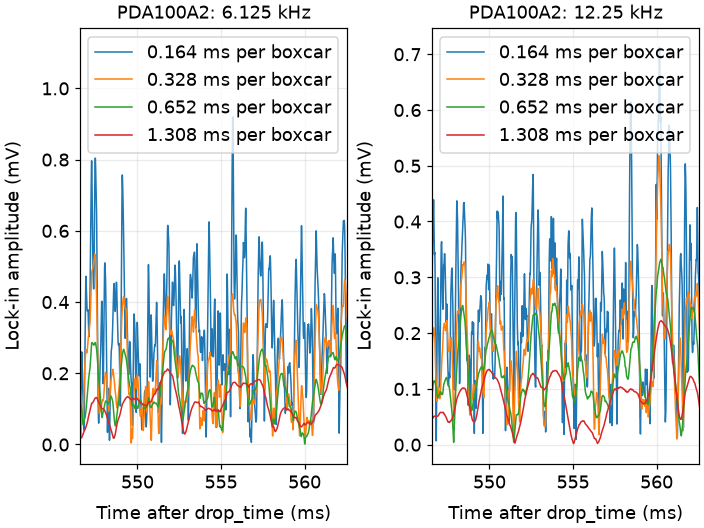

Boxcar length (ms)  Full kernel support (ms)  \
Periods per boxcar Harmonic                                                 
1                  1                      0.164                     0.320   
                   2                      0.164                     0.320   
2                  1                      0.328                     0.648   
                   2                      0.328                     0.648   
4                  1                      0.652                     1.296   
                   2                      0.652                     1.296   
8                  1                      1.308                     2.608   
                   2                      1.308                     2.608   

                             Peak after acquisition (ms)  \
Periods per boxcar Harmonic                                
1                  1                              71.708   
                   2                              76.176   
2                  1                              63.460   
                   2                              76.144   
4                  1                              78.400   
                   2                              76.260   
8                  1                              77.992   
                   2                              76.264   

                             Peak after drop (ms)  Peak amplitude (mV)  \
Periods per boxcar Harmonic                                              
1                  1                      555.708               0.9196   
                   2                      560.176               0.7118   
2                  1                      547.460               0.5343   
                   2                      560.144               0.5178   
4                  1                      562.400               0.3331   
                   2                      560.260               0.3321   
8                  1                      561.992               0.2247   
                   2                      560.264               0.2221   

                             Background complex RMS (mV)  Peak/background RMS  
Periods per boxcar Harmonic                                                    
1                  1                              0.3597               2.5564  
                   2                              0.2437               2.9209  
2                  1                              0.2414               2.2130  
                   2                              0.1768               2.9286  
4                  1                              0.1713               1.9449  
                   2                              0.1298               2.5583  
8                  1                              0.1183               1.8985  
                   2                              0.0923               2.4055

With 0.5–2 ms boxcars, the 2 kHz maximum spans **547.46–562.40 ms** after drop_time. Use this spread to assess sensitivity to smoothing, not as an error bar. In weak data the maximum can move between noise excursions.

In [9]:
# Compare reasonable short averages with a deliberately broader 4 ms boxcar.
sensitivity_rows = []
sensitivity = {}
fig, axes = plt.subplots(1, 2, sharex=True, layout="constrained")
for periods in (1, 2, 4, 8):
    analysis = analyze_shot(shot, reference, n_periods=periods,
                            cloud_center_s=primary["cloud_center_s"], **ANALYSIS_OPTIONS)
    sensitivity[periods] = analysis
    for ax, h in zip(axes, HARMONICS):
        result = analysis["results"][("PDA100A2", h)]
        valid = result["valid"]
        ax.plot(time_after_drop_ms(result["t"][valid]), 1e3 * result["r"][valid],
                label=f"{result['boxcar_ms']:g} ms per boxcar")
        sensitivity_rows.append({"Periods per boxcar": periods, "Harmonic": h,
            "Boxcar length (ms)": result["boxcar_ms"],
            "Full kernel support (ms)": result["support_ms"],
            "Peak after acquisition (ms)": 1e3 * result["peak_time_s"],
            "Peak after drop (ms)": 1e3 * (result["peak_time_s"] + shot["acquisition_after_drop_s"]),
            "Peak amplitude (mV)": 1e3 * result["peak_amp"],
            "Background complex RMS (mV)": 1e3 * result["noise_rms"],
            "Peak/background RMS": result["peak_amp"] / result["noise_rms"]})
for ax, h in zip(axes, HARMONICS):
    ax.set_title(f"PDA100A2: {h * FM_HZ / 1e3:g} kHz", fontdict=title_font)
    ax.set_xlim(time_after_drop_ms(primary["cloud_center_s"] - CLOUD_HALF_WIDTH_S),
                time_after_drop_ms(primary["cloud_center_s"] + CLOUD_HALF_WIDTH_S))
    ax.set_xlabel("Time after drop_time (ms)", fontdict=label_font, labelpad=20)
    ax.set_ylabel("Lock-in amplitude (mV)", fontdict=label_font, labelpad=12)
    ax.legend(prop=legend_font)
show_figure(fig, "averaging_sensitivity")
sensitivity_table = pd.DataFrame(sensitivity_rows)
display(sensitivity_table.set_index(["Periods per boxcar", "Harmonic"]).round(4))

# Print the timing spread over 0.5–2 ms boxcars; do not interpret it as an uncertainty interval.
short_f = sensitivity_table[(sensitivity_table["Harmonic"] == 1)
                            & (sensitivity_table["Periods per boxcar"] <= 4)]
display(Markdown(f"With 0.5–2 ms boxcars, the 2 kHz maximum spans "
                 f"**{short_f['Peak after drop (ms)'].min():.2f}–"
                 f"{short_f['Peak after drop (ms)'].max():.2f} ms** after drop_time. "
                 "Use this spread to assess sensitivity to smoothing, not as an error bar. "
                 "In weak data the maximum can move between noise excursions."))

## Numerical validation and exported results

Check the amplitude normalization and phase with a known sinusoid, then check the recovered timing with a noiseless Gaussian modulation envelope. These numerical checks validate the demodulator, not the optical calibration or experimental interpretation. The synthetic envelope is compared with its **filtered** expected value, since smoothing changes its peak height. The ideal centered envelope must retain its peak to within a sample; the demodulated real waveform is allowed a small peak shift from residual twice-carrier ripple (less than 0.1 ms) and less than 0.5% envelope error.

In [10]:
# Inject a known 5 mV cosine using the independently fitted reference phase.
t = shot["t_pda"]
ref = reference
theta = 2 * np.pi * ref["f_hz"] * (t - shot["sine_start_s"]) + ref["phase_rad"]
test_amp_v = 0.005
test_phase_rad = 0.37
test_voltage = 6.0 + test_amp_v * np.cos(theta + test_phase_rad)
test_z, test_valid, _, _ = complex_lockin(test_voltage, t, shot["fs_pda"], shot, ref,
                                         harmonic=1, n_periods=AVERAGING_PERIODS, switch_guard_s=SWITCH_GUARD_S)
expected_z = test_amp_v * np.exp(1j * test_phase_rad)
relative_error = np.max(np.abs(test_z[test_valid] - expected_z)) / test_amp_v
assert relative_error < 0.002, "Unexpected lock-in amplitude or phase normalization"

# Check the centered envelope separately from finite rejection of the twice-carrier mixing term.
test_center_s = primary["cloud_center_s"]
test_envelope = 0.010 * np.exp(-0.5 * ((t - test_center_s) / 0.001)**2)
gaussian_voltage = 6.0 + test_envelope * np.cos(theta + test_phase_rad)
gaussian_z, gaussian_valid, _, _ = complex_lockin(gaussian_voltage, t, shot["fs_pda"],
                                                  shot, ref, 1, AVERAGING_PERIODS, switch_guard_s=SWITCH_GUARD_S)
expected_envelope = signal.fftconvolve(test_envelope, primary_kernel, mode="same")
gaussian_peak_s = float(t[np.flatnonzero(gaussian_valid)[np.argmax(np.abs(gaussian_z[gaussian_valid]))]])
ideal_peak_s = float(t[np.argmax(expected_envelope)])
assert abs(ideal_peak_s - test_center_s) <= 1.1 / shot["fs_pda"]
# Real cosine mixing also produces a twice-carrier term. Its finite rejection can shift the
# waveform maximum slightly, even though the averaging kernel itself is centered.
assert abs(gaussian_peak_s - test_center_s) < 0.0001
envelope_error_v = np.max(np.abs(np.abs(gaussian_z[gaussian_valid]) - expected_envelope[gaussian_valid]))
relative_envelope_error = envelope_error_v / expected_envelope.max()
assert relative_envelope_error < 0.005
print(f"Known sinusoid: maximum relative amplitude/phase error = {relative_error:.2e}")
print(f"Known Gaussian transit: recovered peak = {1e3 * gaussian_peak_s:.3f} ms "
      f"(injected {1e3 * test_center_s:.3f} ms), envelope error = {1e6 * envelope_error_v:.3f} μV "
      f"({100 * relative_envelope_error:.3f}%)")
print(f"Residual-mixing peak shift in this noiseless example: "
      f"{1e6 * (gaussian_peak_s - test_center_s):.1f} μs; ideal filtered envelope peak: "
      f"{1e3 * ideal_peak_s:.3f} ms")

# Export tables in native units, keeping a unit column where detector units differ.
all_summary = primary["table"].assign(File=FILE_PATH.name, Shot=SHOT_LABEL)
if SAVE_OUTPUTS:
    metadata_table.to_csv(OUTPUT_DIR / "acquisition_metadata.csv")
    reference_table.to_csv(OUTPUT_DIR / "reference_fit.csv")
    all_summary.to_csv(OUTPUT_DIR / "lockin_peak_summary.csv", index=False)
    sensitivity_table.to_csv(OUTPUT_DIR / "averaging_sensitivity.csv", index=False)

    # Save all primary PDA quadratures so later analysis can retain signed phase information.
    exported = pd.DataFrame({"time_after_acquisition_s": shot["t_pda"],
                            "time_after_drop_s": shot["t_pda"] + shot["acquisition_after_drop_s"],
                            "raw_pda_v": shot["pda_v"],
                            "recorded_reference_v": shot["reference_v"]})
    for h in HARMONICS:
        result = primary["results"][("PDA100A2", h)]
        # NaN marks samples invalidated by gating or finite filter support.
        exported[f"X_{h}f_v"] = np.where(result["valid"], result["z"].real, np.nan)
        exported[f"Y_{h}f_v"] = np.where(result["valid"], result["z"].imag, np.nan)
        exported[f"R_{h}f_v"] = np.where(result["valid"], result["r"], np.nan)
    exported.to_csv(OUTPUT_DIR / "pda_lockin_timeseries.csv", index=False)
    print(f"Figures and CSV tables saved to: {OUTPUT_DIR}")

Known sinusoid: maximum relative amplitude/phase error = 1.61e-05
Known Gaussian transit: recovered peak = 70.564 ms (injected 70.565 ms), envelope error = 1.787 μV (0.018%)
Residual-mixing peak shift in this noiseless example: -1.0 μs; ideal filtered envelope peak: 70.564 ms
Figures and CSV tables saved to: C:\Experiments\eedmLabscriptOps\exp12_switchArmsAndLaunch_Absorption\2026\10\15\0002\lockin_analysis_outputs\2026-10-15_0002_exp12_switchArmsAndLaunch_Absorption_1


## MOT loading curve and atom number

The PDA100A pressed against the MOT window is recorded on NI6363 `ai2` (trace `MOT_fluorescence`, exp12 shots from 2026-10-14 on), from 10 ms before the MOT shutter opens until about 15 ms after it closes. It is block-averaged to 10 kHz. Every file is its own shot with its own MOT load, so `_0` and `_1` files each have a curve.

The fit $V(t)=B+A\,(1-e^{-(t-t_\mathrm{open})/\tau})$ runs from the measured shutter opening to coils off:

- $B-V_\mathrm{dark}$ is scattered MOT light with essentially no atoms yet.
- $A\,(1-e^{-T/\tau})$ is the atom fluorescence when the coils switch off, after a load of length $T$.
- $A/\tau$ is the initial loading rate, and $\tau$ is the loading time constant.

The atom number follows from the calibration inputs in the next cell, using the scattering rate $R=(\Gamma/2)\,s/(1+s+(2\delta/\Gamma)^2)$ and the collection solid angle. Times here are seconds after the commanded MOT shutter opening.

File,2026-10-15_0002_exp12_switchArmsAndLaunch_Absorption_1.h5
Raw rate (kS/s),250.0000
Averaged to (kHz),10.0000
Dark before open (mV),59.2955
Dark after close (mV),59.1537
Measured shutter opening (ms),-0.1519
Scattered light B − dark (mV),11.7869
Asymptote A (mV),58.2578
τ (s),2.5318
τ error (s),0.0062
Loading rate A/τ (mV/s),23.0102


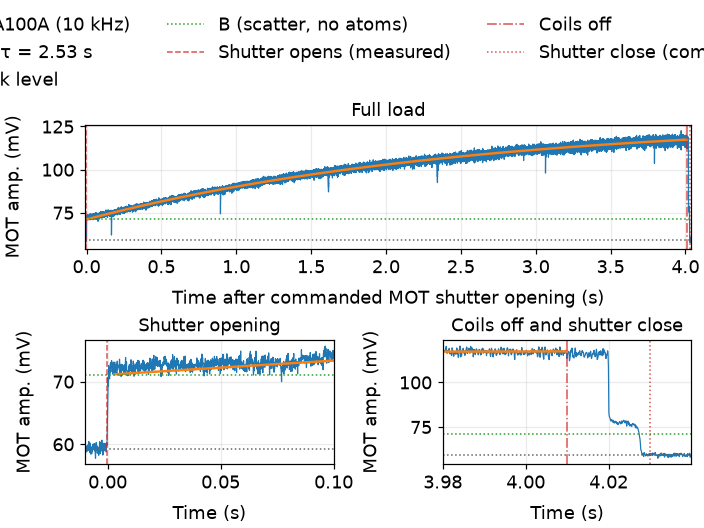

**MOT load:** τ = 2.53 ± 0.01 s; atom fluorescence at coils off 46.3 mV over 11.8 mV of scattered light. That is **1.6e+05 atoms**.

In [ ]:
# MOT loading curve from the PDA100A on ai2; shots without the trace skip this section.
from fluorescence_absorption_lockin import (load_mot_trace, fit_mot_loading,
                                            mot_collection_fraction, mot_atom_number)

# Fill these in to convert volts to atom number; any None skips the conversion.
MOT_CAL = {
    "gain_v_per_a": 4.75e6, #70 dB            # PDA100A gain, high-impedance load (e.g. 50 dB = 4.75e5 V/A)
    "responsivity_a_per_w": 0.55,    # Si at 852 nm, approximate
    "aperture_diameter_m": 0.015,     # clear aperture that limits collection (window or detector)
    "distance_m": 0.18,              # MOT to that aperture
    "transmission": 1.0,             # viewport transmission
    "total_intensity_mw_cm2": 9,  # sum of all MOT beams at the atoms
    "detuning_hz": -5.2227e6*0.15,             # MOT detuning (negative = red)
}

mot = load_mot_trace(FILE_PATH)
if mot is None:
    display(Markdown(f"**No `MOT_fluorescence` trace in {FILE_PATH.name}.** "
                     "MOT loading needs ai2 (exp12 shots from 2026-10-14 on)."))
else:
    mot_fit = fit_mot_loading(mot)
    if all(value is not None for value in MOT_CAL.values()):
        collection = mot_collection_fraction(MOT_CAL["aperture_diameter_m"], MOT_CAL["distance_m"])
        mot_atoms = mot_atom_number(mot_fit["atoms_v_at_coils_off"], MOT_CAL["gain_v_per_a"],
                                    MOT_CAL["responsivity_a_per_w"], collection,
                                    MOT_CAL["total_intensity_mw_cm2"], MOT_CAL["detuning_hz"],
                                    transmission=MOT_CAL["transmission"])
    else:
        collection, mot_atoms = None, None
    mot_table = pd.DataFrame([{
        "File": FILE_PATH.name,
        "Raw rate (kS/s)": mot["fs_raw_hz"] / 1e3, "Averaged to (kHz)": mot["fs_hz"] / 1e3,
        "Dark before open (mV)": 1e3 * mot_fit["dark_v"],
        "Dark after close (mV)": 1e3 * mot_fit["dark_after_close_v"],
        "Measured shutter opening (ms)": 1e3 * mot_fit["t_open_s"],
        "Scattered light B − dark (mV)": 1e3 * mot_fit["scatter_v"],
        "Asymptote A (mV)": 1e3 * mot_fit["asymptote_v"],
        "τ (s)": mot_fit["tau_s"], "τ error (s)": mot_fit["tau_err_s"],
        "Loading rate A/τ (mV/s)": 1e3 * mot_fit["load_rate_v_per_s"],
        "Atom signal at coils off (mV)": 1e3 * mot_fit["atoms_v_at_coils_off"],
        "Last 50 ms − B, direct (mV)": 1e3 * mot_fit["end_minus_baseline_v"],
        "Fit residual RMS (mV)": 1e3 * mot_fit["residual_rms_v"],
        "Collection fraction": collection,
        "Atom number at coils off": mot_atoms,
    }]).set_index("File")
    display(mot_table.T.round(4))

    # Full load on top; the shutter-opening step and the coils-off/shutter-close end below.
    fig, axes = plt.subplot_mosaic([["full", "full"], ["start", "end"]], layout="constrained")
    fit_t = mot["t"][mot_fit["fit_mask"]]
    panels = {"full": ("Full load", mot["t"][0], mot["t"][-1]),
              "start": ("Shutter opening", -0.010, 0.100),
              "end": ("Coils off and shutter close", mot["coils_off_s"] - 0.030, mot["t"][-1])}
    for name, (title, lo, hi) in panels.items():
        ax = axes[name]
        shown = (mot["t"] >= lo) & (mot["t"] <= hi)
        ax.plot(mot["t"][shown], 1e3 * mot["v"][shown], lw=0.8, label="PDA100A (10 kHz)")
        fit_shown = (fit_t >= lo) & (fit_t <= hi)
        ax.plot(fit_t[fit_shown], 1e3 * mot_fit["model"](fit_t[fit_shown]), color="C1", lw=1.6,
                label=f"Fit: τ = {mot_fit['tau_s']:.2f} s")
        ax.axhline(1e3 * mot_fit["dark_v"], color="0.4", ls=":", label="Dark level")
        ax.axhline(1e3 * mot_fit["baseline_v"], color="C2", ls=":", label="B (scatter, no atoms)")
        for x, style, label in ((mot_fit["t_open_s"], "--", "Shutter opens (measured)"),
                                (mot["coils_off_s"], "-.", "Coils off"),
                                (mot["shutter_close_s"], ":", "Shutter close (commanded)")):
            if lo <= x <= hi:
                ax.axvline(x, color="C3", ls=style, alpha=0.8, label=label)
        ax.set_xlim(lo, hi)
        ax.set_title(title, fontdict=title_font)
        ax.set_xlabel("Time after commanded MOT shutter opening (s)" if name == "full" else "Time (s)",
                      fontdict=label_font, labelpad=20)
        ax.set_ylabel("MOT amp. (mV)", fontdict=label_font, labelpad=12)
    handles, labels = axes["full"].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside upper center", ncols=3, frameon=False, prop=legend_font)
    EXPORT_SIZES_INCHES["mot_loading"] = (16, 11)
    show_figure(fig, "mot_loading")

    display(Markdown(
        f"**MOT load:** τ = {mot_fit['tau_s']:.2f} ± {mot_fit['tau_err_s']:.2f} s; "
        f"atom fluorescence at coils off {1e3 * mot_fit['atoms_v_at_coils_off']:.1f} mV "
        f"over {1e3 * mot_fit['scatter_v']:.1f} mV of scattered light. "
        + (f"That is **{mot_atoms:.3g} atoms**." if mot_atoms is not None
           else "Fill in `MOT_CAL` to convert this to an atom number.")))
    if SAVE_OUTPUTS:
        mot_table.to_csv(OUTPUT_DIR / "mot_loading_fit.csv")

## Interpreting a selected shot

The PMT envelope identifies the cloud window independently of the PDA100A2. Report candidate maxima together with off-cloud complex RMS, the largest off-cloud fluctuation, the largest full-gate feature, and the smoothing dependence. A positive magnitude maximum always exists in noise, and these correlated filtered samples do not provide a simple detection p-value. In a weak returning shot, a candidate time is not a secure absorption arrival-time measurement.

The code subtracts stationary coherent pickup using off-cloud portions of the same file. An atom-free synchronized measurement can help separate absorption from time-dependent pickup. Optical depth or atom number requires a detector gain and laser tuning calibration.

The model example is `eedm_jml/daqAnalysisAndExperiments/launch/absorptionLockin/absorptionLockin.ipynb`. These notebooks use its two-boxcar lock-in idea with recorded-reference phase, cumulative-counter handling, file-dependent timing, and finite-filter boundary exclusions.

Implementation references: [SciPy periodogram density units](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.periodogram.html) and [SciPy FFT convolution boundaries](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.fftconvolve.html).